In [1]:
# configuration et GPU
import glob, os, time, math, json, random
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "/kaggle/working/results"; os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", device)
if device.type == "cuda": print(torch.cuda.get_device_name(0))

Device: cuda
Tesla T4


2872 images
dossiers : ['/kaggle/input/datasets/bryanb/abstract-art-gallery/Abstract_gallery/Abstract_gallery', '/kaggle/input/datasets/bryanb/abstract-art-gallery/Abstract_gallery_2/Abstract_gallery_2']
largeur : min 230 | médiane 500 | max 6720
hauteur : min 251 | médiane 500 | max 8192
modes : {'RGB'}


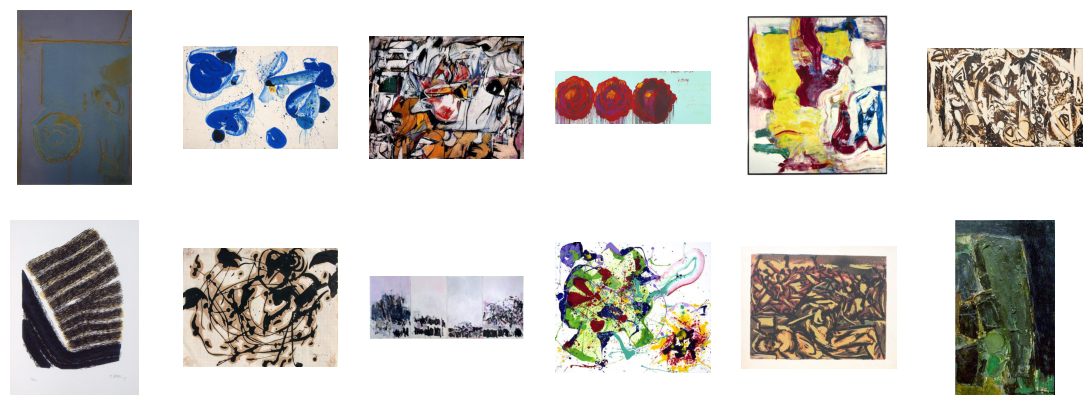

In [2]:
# découverte du dataset
files = sorted({p for e in ("jpg", "jpeg", "png", "JPG", "JPEG", "PNG")
                for p in glob.glob(f"/kaggle/input/**/*.{e}", recursive=True)})
assert files, "aucune image trouvée : ajoute le dataset Abstract Art Gallery avec Add Input"
print(len(files), "images")
print("dossiers :", sorted({os.path.dirname(p) for p in files})[:10])

rng = random.Random(SEED)
sample = rng.sample(files, min(200, len(files)))
w, h = np.array([Image.open(p).size for p in sample]).T
print(f"largeur : min {w.min()} | médiane {int(np.median(w))} | max {w.max()}")
print(f"hauteur : min {h.min()} | médiane {int(np.median(h))} | max {h.max()}")
print("modes :", {Image.open(p).mode for p in sample[:50]})

fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for a, p in zip(ax.ravel(), rng.sample(files, min(12, len(files)))):
    a.imshow(Image.open(p).convert("RGB")); a.axis("off")
plt.show()

2872 images chargées (0 ignorées) en 224 s | (2872, 3, 64, 64)


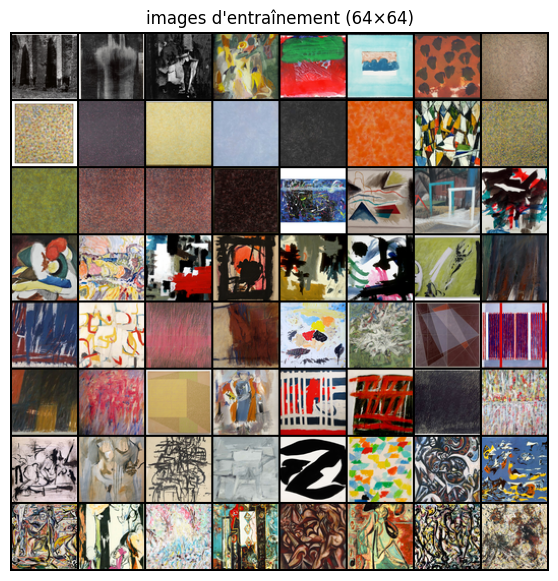

In [3]:
# chargement des images en 64×64
from torchvision.utils import make_grid
IMG = 64

def load_img(p):
    im = Image.open(p); im.draft("RGB", (IMG * 2, IMG * 2)); im = im.convert("RGB")
    w, h = im.size; s = IMG / min(w, h)                   # petit côté ramené à 64, puis recadrage central
    im = im.resize((max(IMG, round(w * s)), max(IMG, round(h * s))), Image.LANCZOS)
    w, h = im.size; l, t = (w - IMG) // 2, (h - IMG) // 2
    return np.asarray(im.crop((l, t, l + IMG, t + IMG)))

t0 = time.time(); arr, bad = [], 0
for p in files:
    try: arr.append(load_img(p))
    except Exception: bad += 1
real_u8 = torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2).contiguous()     # (N, 3, 64, 64), uint8, sur le CPU
N = len(real_u8)
print(f"{N} images chargées ({bad} ignorées) en {time.time() - t0:.0f} s | {tuple(real_u8.shape)}")

def to_float(u8): return u8.float().div(127.5).sub(1.0)                          # [0, 255] -> [-1, 1]
def grid_img(batch, nrow=8):
    return make_grid(batch.detach().cpu().float(), nrow=nrow, normalize=True,
                     value_range=(-1, 1), padding=2).permute(1, 2, 0).numpy()

plt.figure(figsize=(7, 7)); plt.imshow(grid_img(to_float(real_u8[:64])))
plt.axis("off"); plt.title("images d'entraînement (64×64)"); plt.show()

In [4]:
#  modèles, perte, initialisation, optimiseurs
nz, ngf, ndf = 100, 64, 64

class G(nn.Module):
    def __init__(self):
        super().__init__()
        def up(i, o, k=4, s=2, p=1):
            return [nn.ConvTranspose2d(i, o, k, s, p, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.net = nn.Sequential(*up(nz, ngf * 8, 4, 1, 0), *up(ngf * 8, ngf * 4), *up(ngf * 4, ngf * 2), *up(ngf * 2, ngf),
                                 nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False), nn.Tanh())       # sortie 3×64×64 dans [-1, 1]
    def forward(self, z): return self.net(z.view(-1, nz, 1, 1))

class D(nn.Module):
    def __init__(self):
        super().__init__()
        def down(i, o, bn=True):
            return [nn.Conv2d(i, o, 4, 2, 1, bias=False)] + ([nn.BatchNorm2d(o)] if bn else []) + [nn.LeakyReLU(0.2, True)]
        self.net = nn.Sequential(*down(3, ndf, False), *down(ndf, ndf * 2), *down(ndf * 2, ndf * 4), *down(ndf * 4, ndf * 8),
                                 nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False))
    def forward(self, x): return self.net(x).view(-1)                                              # logits

def init_w(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)): nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d): nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

netG, netD = G().to(device), D().to(device)
netG.apply(init_w); netD.apply(init_w)
criterion = nn.BCEWithLogitsLoss()
optG = torch.optim.Adam(netG.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = torch.optim.Adam(netD.parameters(), lr=2e-4, betas=(0.5, 0.999))

print("paramètres G :", sum(p.numel() for p in netG.parameters()), "| D :", sum(p.numel() for p in netD.parameters()))
print(netG(torch.randn(2, nz, device=device)).shape, netD(torch.randn(2, 3, 64, 64, device=device)).shape)   # [2,3,64,64] et [2]

paramètres G : 3576704 | D : 2765568
torch.Size([2, 3, 64, 64]) torch.Size([2])


In [5]:
#  DataLoader et entraînement
from torch.utils.data import DataLoader, TensorDataset
BATCH, STEPS, REAL_LABEL = 64, 6000, 0.9
loader = DataLoader(TensorDataset(real_u8), batch_size=BATCH, shuffle=True, drop_last=True, pin_memory=True)
def batch_stream():
    while True:
        for (xb,) in loader: yield xb
stream = batch_stream()

fixed_z = torch.randn(64, nz, device=device)
hist = {k: [] for k in ["step", "lossD", "lossG", "Dx", "DGz1", "DGz2"]}
SNAP_AT, snaps, step = (250, 500, 1000, 2000, 3000, 4500, 6000), {}, 0

def train(n_steps):
    global step
    for _ in range(n_steps):
        real = to_float(next(stream).to(device, non_blocking=True))
        flip = (torch.rand(len(real), device=device) < 0.5).view(-1, 1, 1, 1)
        real = torch.where(flip, real.flip(3), real)                      # retournement horizontal aléatoire
        # 1) discriminateur : images réelles (étiquette 0,9) et générées (étiquette 0)
        netD.zero_grad()
        out_r = netD(real); loss_r = criterion(out_r, torch.full_like(out_r, REAL_LABEL))
        fake = netG(torch.randn(len(real), nz, device=device))
        out_f = netD(fake.detach()); loss_f = criterion(out_f, torch.zeros_like(out_f))
        (loss_r + loss_f).backward(); optD.step()
        # 2) générateur : il veut que le discriminateur réponde « réel » (étiquette 1)
        netG.zero_grad()
        out_g = netD(fake); loss_g = criterion(out_g, torch.ones_like(out_g))
        loss_g.backward(); optG.step()
        step += 1
        if step % 50 == 0:
            vals = [step, (loss_r + loss_f).item(), loss_g.item(), torch.sigmoid(out_r).mean().item(),
                    torch.sigmoid(out_f).mean().item(), torch.sigmoid(out_g).mean().item()]
            for k, v in zip(hist, vals): hist[k].append(v)
        if step in SNAP_AT:
            with torch.no_grad(): snaps[step] = netG(fixed_z).cpu()
        if step % 1000 == 0:
            print(f"pas {step:5d} | D {hist['lossD'][-1]:.3f} | G {hist['lossG'][-1]:.3f} | D(x) {hist['Dx'][-1]:.2f} "
                  f"| D(G(z)) {hist['DGz1'][-1]:.2f} -> {hist['DGz2'][-1]:.2f} | {time.time() - t0:.0f} s")

t0 = time.time(); train(20); torch.cuda.synchronize()
dt = (time.time() - t0) / 20
print(f"{dt * 1000:.0f} ms par pas -> environ {dt * STEPS / 60:.1f} min pour {STEPS} pas (estimation prudente)")
train(STEPS - 20)
torch.cuda.synchronize(); gan_time = time.time() - t0
print(f"Entraînement terminé : {step} pas (environ {step * BATCH / N:.0f} époques) en {gan_time:.0f} s")

108 ms par pas -> environ 10.8 min pour 6000 pas (estimation prudente)
pas  1000 | D 0.547 | G 5.690 | D(x) 0.77 | D(G(z)) 0.09 -> 0.01 | 82 s
pas  2000 | D 0.492 | G 3.964 | D(x) 0.77 | D(G(z)) 0.06 -> 0.02 | 169 s
pas  3000 | D 0.644 | G 4.775 | D(x) 0.84 | D(G(z)) 0.21 -> 0.01 | 255 s
pas  4000 | D 0.546 | G 5.135 | D(x) 0.94 | D(G(z)) 0.16 -> 0.01 | 341 s
pas  5000 | D 0.671 | G 2.533 | D(x) 0.67 | D(G(z)) 0.09 -> 0.10 | 428 s
pas  6000 | D 0.436 | G 4.592 | D(x) 0.85 | D(G(z)) 0.06 -> 0.02 | 514 s
Entraînement terminé : 6000 pas (environ 134 époques) en 514 s


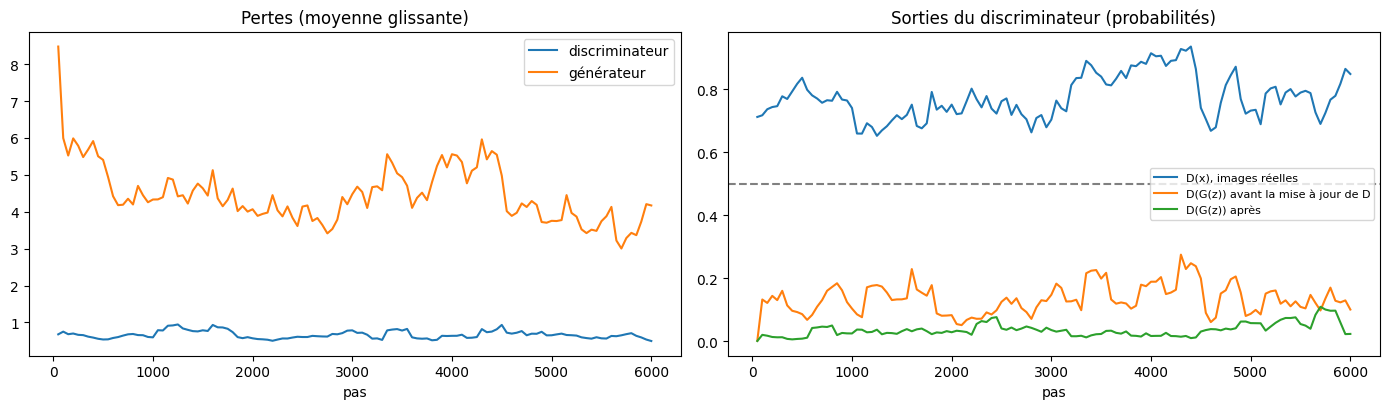

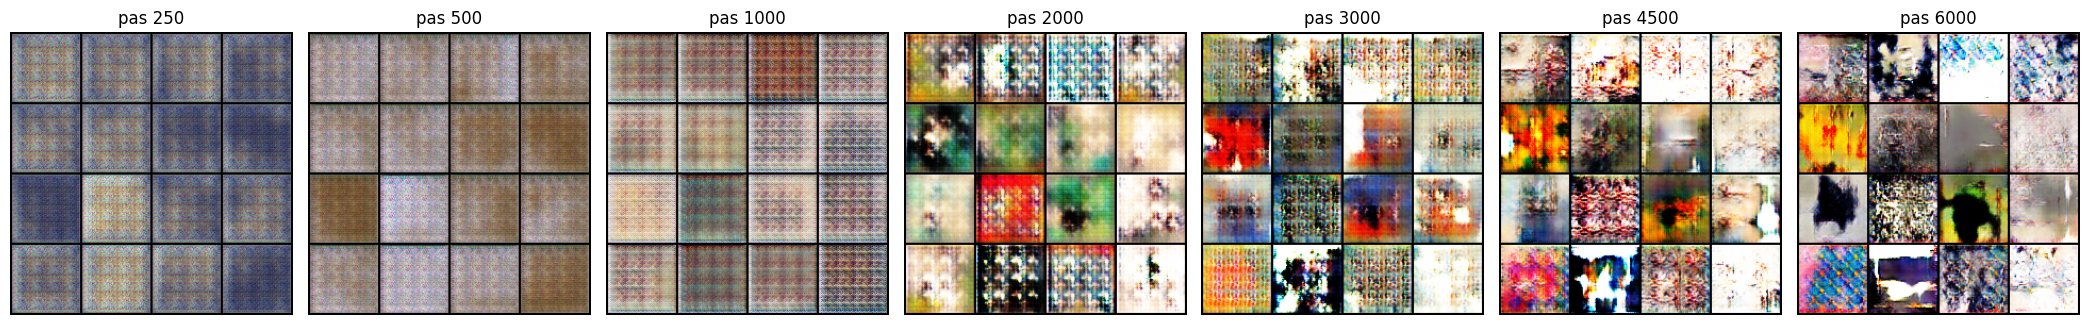

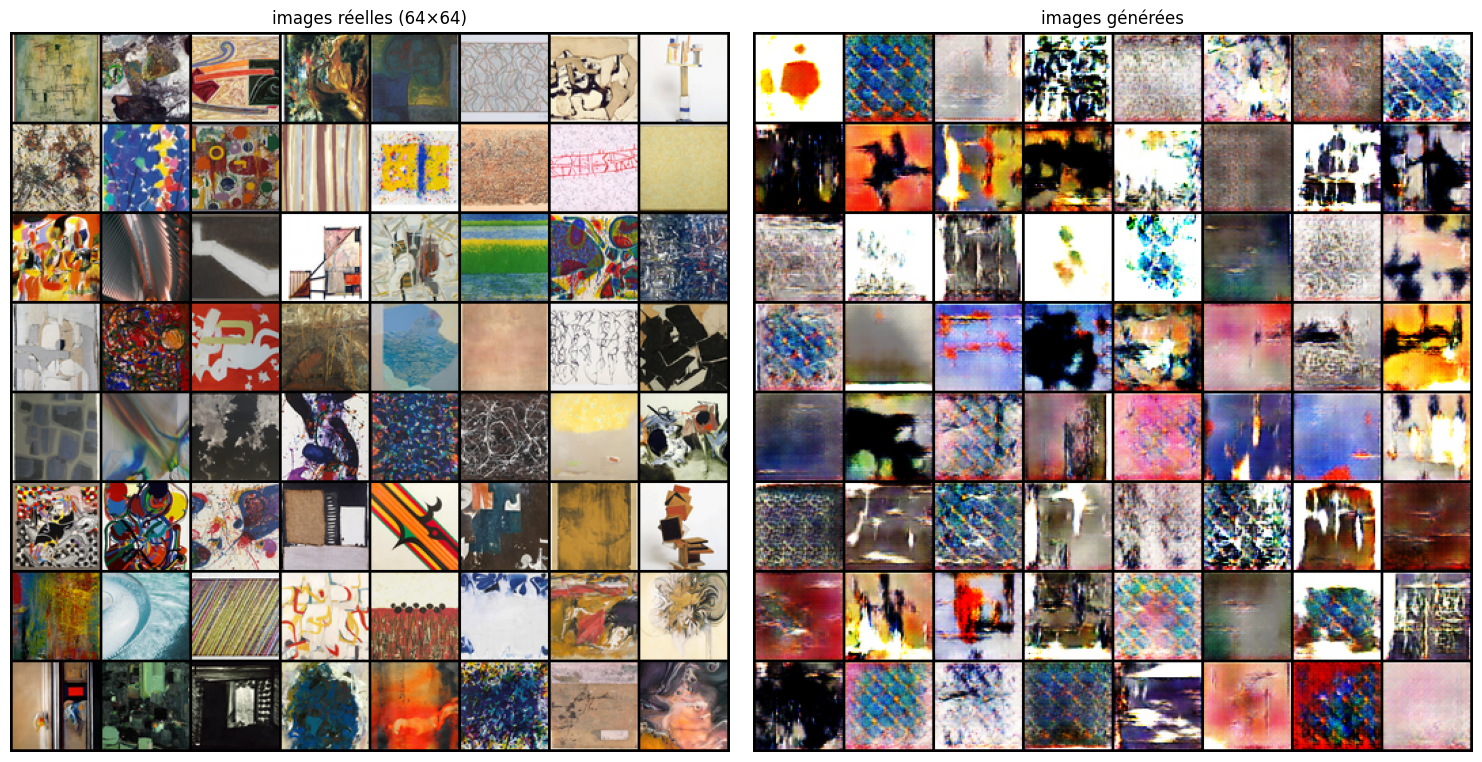

{
 "moyenne_RGB_reelles": [
  0.16080568730831146,
  0.04859339818358421,
  -0.052976757287979126
 ],
 "moyenne_RGB_generees": [
  0.15772171318531036,
  0.0150001784786582,
  -0.003065854776650667
 ],
 "ecart_type_RGB_reelles": [
  0.5784332156181335,
  0.5486131310462952,
  0.5541189908981323
 ],
 "ecart_type_RGB_generees": [
  0.6375202536582947,
  0.6095336675643921,
  0.6108550429344177
 ],
 "diversite_reelles": 40.081336975097656,
 "diversite_generees": 44.839847564697266,
 "distance_au_plus_proche_reel__generees": 23.653827667236328,
 "distance_au_plus_proche_reel__reelles": 15.129294395446777
}


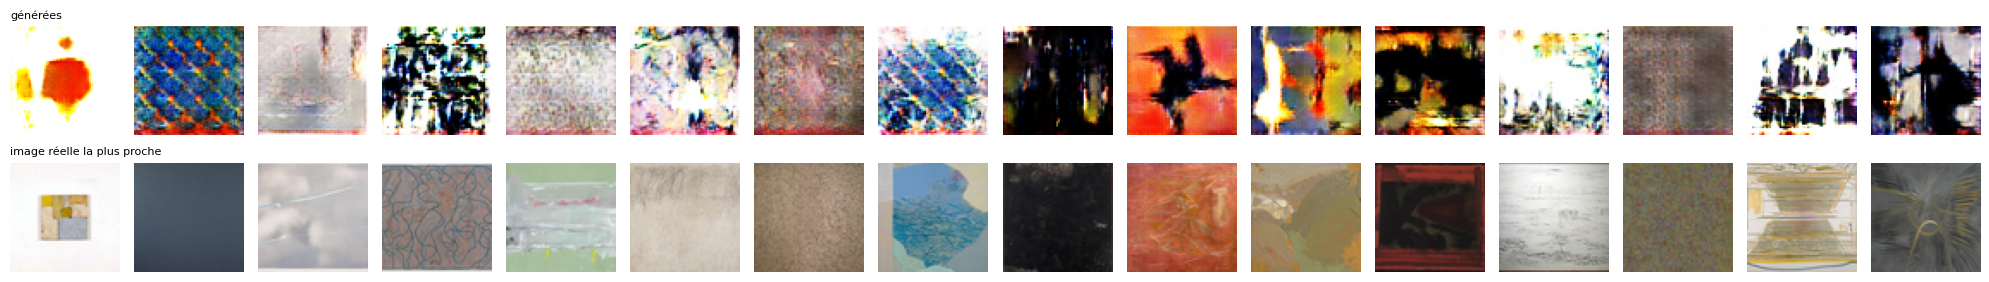

['gan_curves.png', 'gan_evolution.png', 'gan_generator.pt', 'gan_nearest_real.png', 'gan_real_vs_fake.png', 'results_gan.json']


In [6]:
# évaluation, comparaison, sauvegarde
import pandas as pd, zipfile
sm = lambda v, w=5: pd.Series(v).rolling(w, min_periods=1).mean().values

# 1) Courbes de pertes et sorties du discriminateur
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(hist["step"], sm(hist["lossD"]), label="discriminateur"); ax[0].plot(hist["step"], sm(hist["lossG"]), label="générateur")
ax[0].set(title="Pertes (moyenne glissante)", xlabel="pas"); ax[0].legend()
ax[1].plot(hist["step"], sm(hist["Dx"]), label="D(x), images réelles")
ax[1].plot(hist["step"], sm(hist["DGz1"]), label="D(G(z)) avant la mise à jour de D")
ax[1].plot(hist["step"], sm(hist["DGz2"]), label="D(G(z)) après")
ax[1].axhline(0.5, ls="--", c="gray"); ax[1].set(title="Sorties du discriminateur (probabilités)", xlabel="pas"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gan_curves.png", dpi=150); plt.show()

# 2) Évolution des images générées avec un bruit fixe
keys = sorted(snaps); fig, ax = plt.subplots(1, len(keys), figsize=(3 * len(keys), 3.3))
for a, k in zip(np.atleast_1d(ax), keys): a.imshow(grid_img(snaps[k][:16], nrow=4)); a.set_title(f"pas {k}"); a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gan_evolution.png", dpi=150); plt.show()

# 3) Images générées contre images réelles
torch.manual_seed(SEED)
with torch.no_grad(): fake = torch.cat([netG(torch.randn(64, nz, device=device)) for _ in range(4)]).cpu()      # 256 images
allr = to_float(real_u8.to(device)); idx = torch.randperm(N, device=device)[:64]
fig, ax = plt.subplots(1, 2, figsize=(15, 7.5))
ax[0].imshow(grid_img(allr[idx])); ax[0].set_title("images réelles (64×64)")
ax[1].imshow(grid_img(fake[:64])); ax[1].set_title("images générées"); [a.axis("off") for a in ax]
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gan_real_vs_fake.png", dpi=150); plt.show()

# 4) Contrôles chiffrés : couleurs, diversité (effondrement des modes) et copie des données
small = lambda x: torch.nn.functional.avg_pool2d(x, 2).flatten(1)
f64 = fake[:64].to(device)
div_real, div_fake = torch.pdist(small(allr[idx])).mean().item(), torch.pdist(small(f64)).mean().item()
R = small(allr)
d_gen = torch.cdist(small(fake[:16].to(device)), R)
nn_idx, nn_gen = d_gen.argmin(1), d_gen.min(1).values.mean().item()
d_real = torch.cdist(small(allr[idx[:16]]), R).masked_fill(lambda_ := None, 0) if False else torch.cdist(small(allr[idx[:16]]), R)
nn_real = d_real.masked_fill(d_real < 1e-6, float("inf")).min(1).values.mean().item()
stats = {"moyenne_RGB_reelles": allr.mean((0, 2, 3)).tolist(), "moyenne_RGB_generees": fake.mean((0, 2, 3)).tolist(),
         "ecart_type_RGB_reelles": allr.std((0, 2, 3)).tolist(), "ecart_type_RGB_generees": fake.std((0, 2, 3)).tolist(),
         "diversite_reelles": div_real, "diversite_generees": div_fake,
         "distance_au_plus_proche_reel__generees": nn_gen, "distance_au_plus_proche_reel__reelles": nn_real}
print(json.dumps(stats, indent=1))

fig, ax = plt.subplots(2, 16, figsize=(20, 3))
for i in range(16):
    ax[0, i].imshow(grid_img(fake[i:i+1], 1)); ax[1, i].imshow(grid_img(allr[nn_idx[i]:nn_idx[i]+1], 1))
    ax[0, i].axis("off"); ax[1, i].axis("off")
ax[0, 0].set_title("générées", fontsize=8, loc="left"); ax[1, 0].set_title("image réelle la plus proche", fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gan_nearest_real.png", dpi=150); plt.show()

# 5) Sauvegarde (sans les poids)
json.dump({"images": N, "steps": step, "batch": BATCH, "temps_s": gan_time, "nz": nz, "lr": 2e-4, "real_label": REAL_LABEL,
           "history": hist, "stats": stats}, open(f"{OUT_DIR}/results_gan.json", "w"), indent=1)
torch.save(netG.state_dict(), f"{OUT_DIR}/gan_generator.pt")
with zipfile.ZipFile("/kaggle/working/results_02.zip", "w") as z:
    for f in sorted(glob.glob(f"{OUT_DIR}/*")):
        if not f.endswith(".pt"): z.write(f, os.path.basename(f))
print(sorted(os.listdir(OUT_DIR)))